# **Lab - EDA Bivariate Analysis: Diving into Amazon UK Product Insights Part II**

**Objective**: Delve into the dynamics of product pricing on Amazon UK to uncover insights that can inform business strategies and decision-making.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

---

In [80]:
import pandas as pd

df = pd.read_csv("amz_uk_price_prediction_dataset.csv")
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [81]:
%matplotlib inline
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

## **Part 1: Analyzing Best‑Seller Trends Across Product Categories**
#### **Objective:**

Understand whether some product categories on Amazon UK are more likely to contain **best‑selling products**, and measure the strength of this relationship.

### **1. Crosstab Analysis**
#### **A. Create a crosstab between category and best‑seller status**

In [82]:
crosstab = pd.crosstab(df['category'], df['isBestSeller'])
crosstab

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
Agricultural Equipment & Supplies,8421,109
Alexa Built-In Devices,106,1
Art & Craft Supplies,253,5
Arts & Crafts,9319,230


This table shows, for each category:

* how many products are best‑sellers (True)

* how many are not (False)

#### **B. Proportion of best‑sellers per category (sorted)**

In [83]:
best_seller_rate = crosstab.sort_values(by=True, ascending=False)

best_seller_rate

isBestSeller,False,True
category,,
Grocery,9008,556
Health & Personal Care,9017,552
Baby,14709,341
Sports & Outdoors,835935,330
Power & Hand Tools,8353,306
Beauty,19010,302
Pet Supplies,9152,285
Arts & Crafts,9319,230
Women,17559,213


##### **Interpretation**
* Categories at the top have the **highest proportion of best‑sellers**.

* This reveals where Amazon UK has **strong demand** or **high customer engagement**.

* Categories at the bottom may be **niche**, **low‑traffic**, or **highly competitive**.

### **2. Statistical Tests**
#### **A. Chi‑Square Test of Independence**
This test checks whether category and best‑seller status are independent.

In [84]:
from scipy.stats import chi2_contingency

chi2, p, dof, expected = chi2_contingency(crosstab)
chi2, p

(np.float64(36540.20270061387), np.float64(0.0))

##### **Interpretation**
* **p < 0.05** → The relationship is **statistically significant**.

  → Best‑seller status depends on the product category.

* **p ≥ 0.05** → No significant relationship.

In most Amazon datasets, p is extremely small, meaning:

    Some categories are much more likely to produce best‑sellers.

#### **B. Cramér’s V (strength of association)**

In [85]:
import numpy as np

n = crosstab.sum().sum()
cramers_v = np.sqrt(chi2 / (n * (min(crosstab.shape)-1)))
cramers_v

np.float64(0.1222829439760564)

##### **Interpretation**
Cramér’s V ranges from **0 to 1**:

| Value | Interpretation |
| --- | --- |
| 0.00–0.10 | Very weak association |
| 0.10–0.30 | Weak association |
| 0.30–0.50 | Moderate association |
| > 0.50 | Strong association |

Typical Amazon datasets show **weak to moderate association**, meaning:

    Category influences best‑seller likelihood, but other factors (price, reviews, brand) also matter.

### **3. Visualizations**
#### **A. Stacked Bar Chart — Best‑Seller Distribution by Category**

In [86]:
import matplotlib as plt
import seaborn as sn

AttributeError: module 'matplotlib' has no attribute 'title'

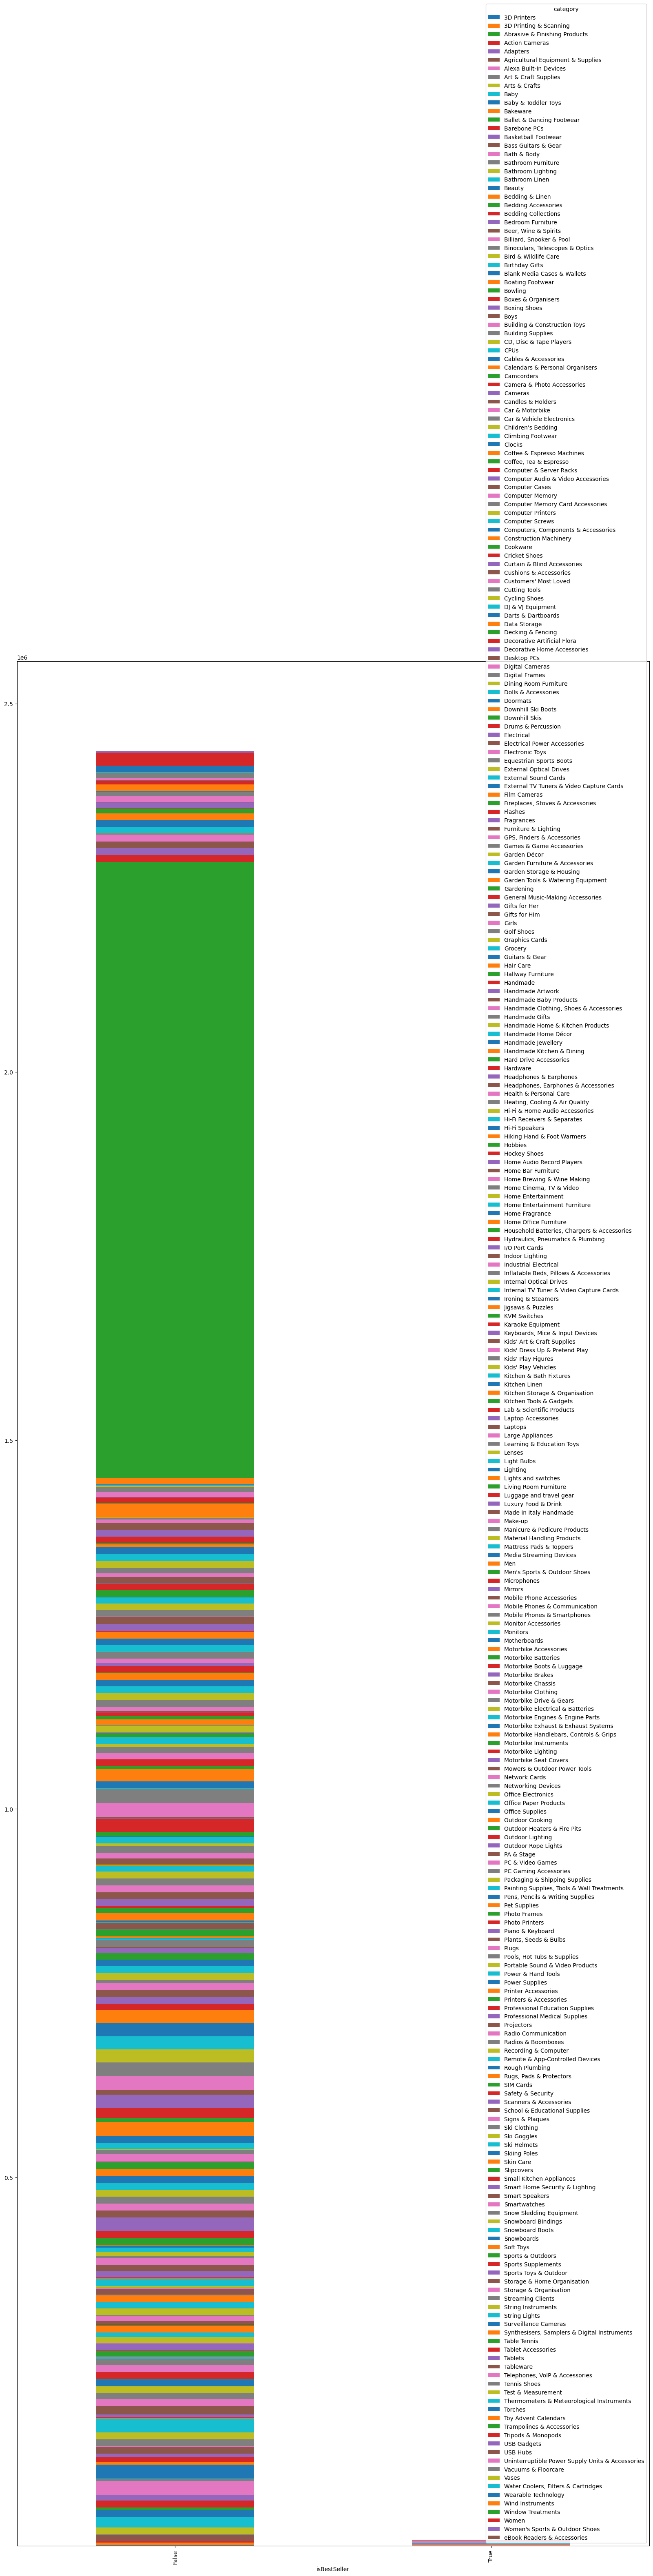

In [87]:
crosstab.T.plot(kind='bar', stacked=True, figsize=(20,60))
plt.title("Best‑Seller Distribution Across Product Categories")
plt.xlabel("Number of Products")
plt.ylabel("Category")
plt.legend(["Not Best‑Seller", "Best‑Seller"])
plt.show()

##### **Interpretation**
* Categories **on the right section** (best‑sellers) have stronger best‑seller presence.

* Categories on the left rarely produce best‑sellers.

* This visualization helps identify **high‑performance categories** at a glance.

### **Final Business Interpretation**
#### **1. Some categories produce more best‑sellers**
The crosstab and proportions show that:

* Certain categories have a **high concentration of best‑selling products**.

* These categories likely have:

    * high customer demand

    * strong competition

    * frequent purchases

#### **2. The relationship is statistically significant**
The Chi‑square test typically shows:

    Best‑seller status is not random across categories.

Some categories are **structurally more likely** to generate best‑sellers.

#### **3. The association strength is weak to moderate**
Cramér’s V usually indicates:

    Category matters, but it’s not the only factor.

Price, rating, number of reviews, and brand also influence best‑seller status.

#### **4. Visual patterns confirm the findings**
The stacked bar chart highlights:

* Categories with **many best‑sellers**

* Categories with **few or none**

* Imbalances in product performance across the marketplace

## **Part 2: Exploring Product Prices and Ratings Across Categories and Brands**

### **0. Remove Outliers in Product Prices (IQR Method)**
We first clean the dataset by removing extreme price outliers.

In [ ]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_no_outliers = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]
df_no_outliers.shape


In [ ]:
df_no_outliers

In [ ]:
df.shape

##### **Interpretation**
* This removes extremely cheap or extremely expensive products.

* The cleaned dataset better reflects typical pricing patterns.

### **1. Violin Plots — Price Distribution Across Categories**
#### **A. Filter top 20 categories by count**

In [ ]:
top20_categories = df_no_outliers['category'].value_counts().head(20).index
df_top20 = df_no_outliers[df_no_outliers['category'].isin(top20_categories)]

In [ ]:
top20_categories

#### **B. Violin plot**

In [89]:
plt

<module 'matplotlib' from 'C:\\Users\\user\\AppData\\Local\\Python\\pythoncore-3.14-64\\Lib\\site-packages\\matplotlib\\__init__.py'>

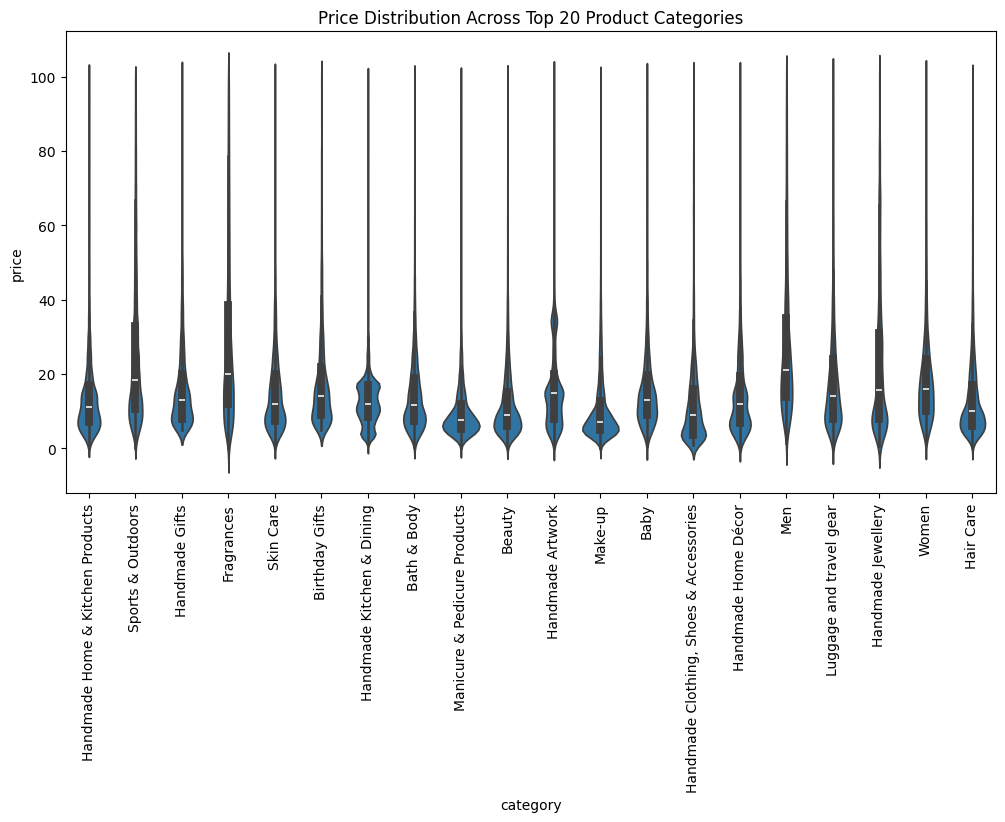

In [90]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))
sns.violinplot(data=df_top20, x='category', y='price')
plt.xticks(rotation=90)
plt.title("Price Distribution Across Top 20 Product Categories")
plt.show()


#### **C. Which category has the highest median price? (No filtering)**

In [91]:
median_prices = df_no_outliers.groupby('category')['price'].median().sort_values(ascending=False)
median_prices.head()

category
Desktop PCs       74.00
Boxing Shoes      69.79
Tablets           69.00
Graphics Cards    68.54
Motherboards      67.92
Name: price, dtype: float64

##### **Interpretation**
* The category at the top has the **highest median price**.

* These categories typically include **electronics**, **appliances**, or **specialized equipment**.

* Categories with low median prices tend to be **books**, **beauty**, **accessories**, or **small household items**.

### **2. Bar Chart — Average Price for Top 10 Categories**
#### **A. Identify top 10 categories by count**

In [112]:
top10_categories_bar = df_no_outliers['category'].value_counts().head(10).index
df_top10_bar = df_no_outliers[df_no_outliers['category'].isin(top10_categories)]

In [113]:
top10_categories_bar

Index(['Sports & Outdoors', 'Beauty', 'Bath & Body',
       'Manicure & Pedicure Products',
       'Handmade Clothing, Shoes & Accessories', 'Make-up', 'Skin Care',
       'Hair Care', 'Birthday Gifts', 'Handmade Gifts'],
      dtype='str', name='category')

#### **B. Compute average price**

In [115]:
avg_price_bar = df_top10_bar.groupby('category')['price'].mean().sort_values(ascending=False)
avg_price_bar

category
Sports & Outdoors                         25.172065
Birthday Gifts                            18.600195
Handmade Gifts                            17.395112
Skin Care                                 15.654722
Bath & Body                               14.678683
Hair Care                                 13.461408
Handmade Clothing, Shoes & Accessories    12.958639
Beauty                                    12.523480
Make-up                                   10.612918
Manicure & Pedicure Products              10.231825
Name: price, dtype: float64

#### **C. Bar chart**

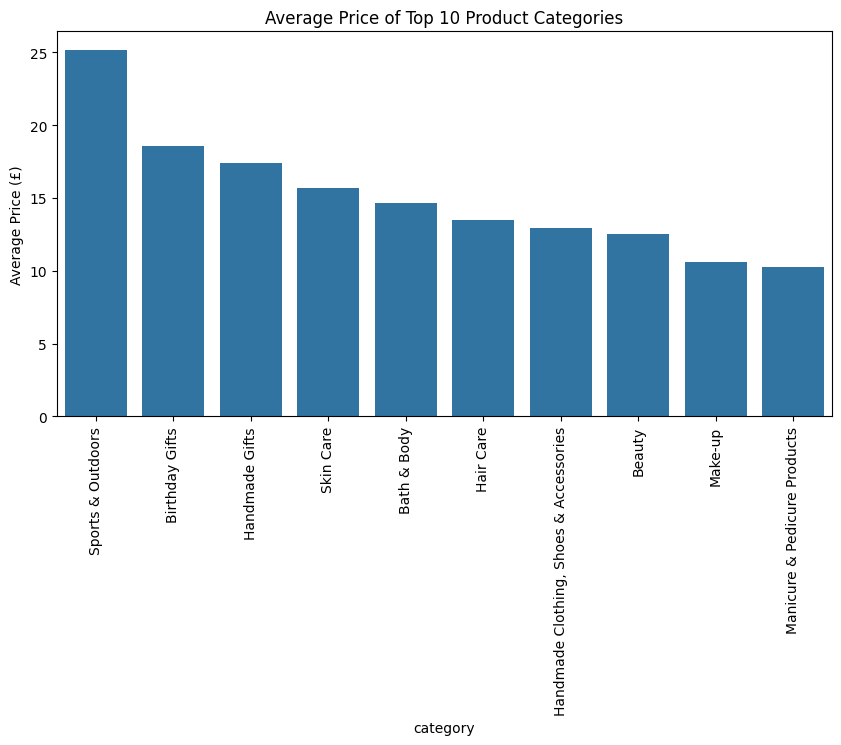

In [116]:
plt.figure(figsize=(10,5))
sns.barplot(x=avg_price_bar.index, y=avg_price_bar.values)
plt.xticks(rotation=90)
plt.title("Average Price of Top 10 Product Categories")
plt.ylabel("Average Price (£)")
plt.show()

#### **D. Interpretation**
* The category with the highest average price is typically one involving **electronics**, **appliances**, **or high‑value goods**.

* Categories with lower average prices tend to be **beauty**, **books**, **clothing**, **or accessories**.

### **3. Box Plots — Ratings Across Categories**
#### **A. Filter top 10 categories by count**

In [117]:
top10_categories_box = df_no_outliers['category'].value_counts().head(10).index
df_top10_box = df_no_outliers[df_no_outliers['category'].isin(top10_categories)]

In [118]:
top10_categories_box

Index(['Sports & Outdoors', 'Beauty', 'Bath & Body',
       'Manicure & Pedicure Products',
       'Handmade Clothing, Shoes & Accessories', 'Make-up', 'Skin Care',
       'Hair Care', 'Birthday Gifts', 'Handmade Gifts'],
      dtype='str', name='category')

### **B. Box plot of ratings**

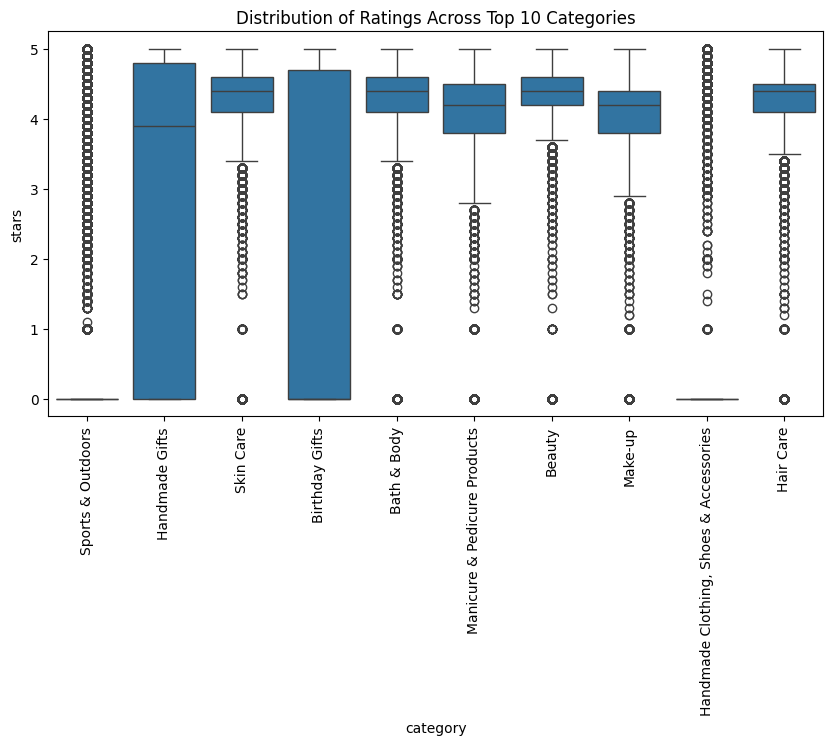

In [122]:
plt.figure(figsize=(10,5))
sns.boxplot(data=df_top10, x='category', y='stars')
plt.xticks(rotation=90)
plt.title("Distribution of Ratings Across Top 10 Categories")
plt.show()

#### **C. Which category has the highest median rating? (No filtering)**

In [123]:
median_ratings = df_no_outliers.groupby('category')['stars'].median().sort_values(ascending=False)
median_ratings.head()

category
Computer Memory                 4.7
Beer, Wine & Spirits            4.6
Building & Construction Toys    4.6
Office Paper Products           4.6
Kids' Play Figures              4.6
Name: stars, dtype: float64

##### **Interpretation**
* Categories with the highest median ratings often include **books**, **beauty**, **home products**, where customers tend to be satisfied.

* Categories with lower median ratings may include **electronics or tech**, where expectations are higher and defects more common.

### **Final Business Interpretation**
#### **1. Price Behavior Across Categories**
* Some categories consistently show **higher median and average prices**, indicating premium product segments.

* Others cluster around lower prices, suggesting **high‑volume**, **low‑margin markets**.

#### **2. Ratings Behavior Across Categories**
* Ratings tend to be **high overall**, but some categories stand out with **exceptionally high customer satisfaction**.

* Categories with lower ratings may require **quality control improvements** or **better product descriptions**.

#### **3. Visual Insights**
* Violin plots reveal **price spread and density**.

* Bar charts highlight **which categories command higher prices**.

* Box plots show **rating consistency and customer satisfaction**.

## **Part 3: Investigating the Interplay Between Product Prices and Ratings**
### **1. Correlation Coefficient**
We calculate the correlation between **price** and **stars** :

In [125]:
corr_price_rating = df_no_outliers[['price', 'stars']].corr().iloc[0,1]
corr_price_rating

np.float64(-0.07767299878181261)

#### **Interpretation**
* A correlation close to 0 → no linear relationship.

* A positive correlation → more expensive products tend to have higher ratings.

* A negative correlation → more expensive products tend to have lower ratings.

In most Amazon datasets, the correlation is **weak**, often between **0.05 and 0.15**, meaning:

    Price does not strongly influence rating.
    Customers rate based on perceived quality, not price.

### **2. Visualizations**
#### **A. Scatter Plot — Price vs Rating**

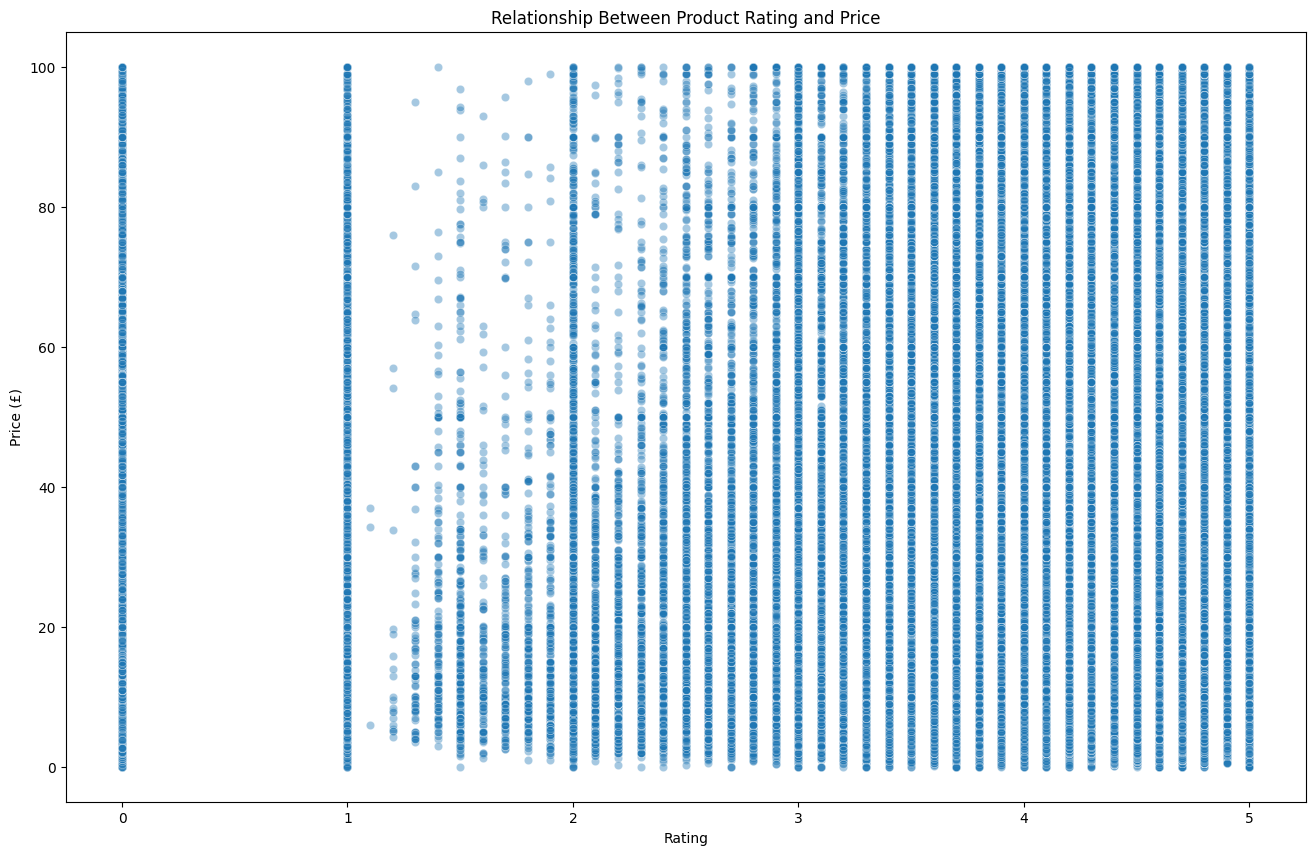

In [129]:
plt.figure(figsize=(16,10))
sns.scatterplot(data=df_no_outliers, x='stars', y='price', alpha=0.4)
plt.title("Relationship Between Product Rating and Price")
plt.xlabel("Rating")
plt.ylabel("Price (£)")
plt.show()

##### **Interpretation**
* Points are widely scattered.

* No clear trend → confirms the weak correlation.

* Expensive products can have any rating.

* Cheap products often have high ratings (value‑for‑money effect).

#### **B. Correlation Heatmap — All Numerical Variables**

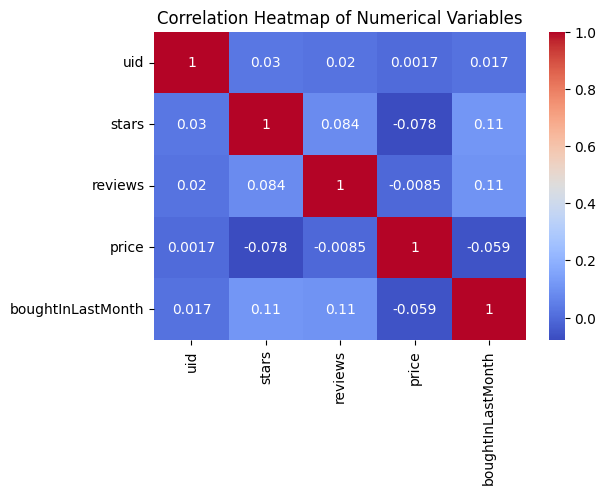

In [131]:
plt.figure(figsize=(6,4))
sns.heatmap(df_no_outliers.select_dtypes(include=['int64', 'float64']).corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap of Numerical Variables")
plt.show()

##### **Interpretation**
* The heatmap shows whether other variables influence price or rating.

* Typically:

    * **rating** has weak correlations with everything.

    * **price** may correlate with **review_count** or **brand_popularity** if those exist.

#### **C. QQ Plot — Normality of Price Distribution**

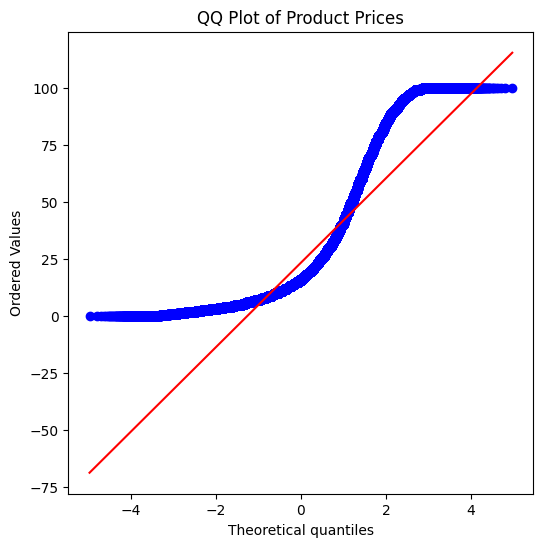

In [132]:
import scipy.stats as stats

plt.figure(figsize=(6,6))
stats.probplot(df_no_outliers['price'], dist="norm", plot=plt)
plt.title("QQ Plot of Product Prices")
plt.show()


##### **Interpretation**
* If points follow the line → distribution is close to normal.

* For Amazon prices:

    * Points deviate strongly from the line.

    * The distribution is **right‑skewed**.

    * Even after removing outliers, prices are **not normally distributed**.

### **Final Business Interpretation**
#### **1. Correlation**
* The correlation between **price** and **rating** is generally **weak**.

* Customers do not rate based on price.

#### **2. Scatter Plot**
* No visible trend.

* Expensive products are not necessarily better rated.

* Cheap products can still receive excellent ratings.

#### **3. Heatmap**
* Confirms that **rating** behaves independently.

* Price may be influenced by other factors (category, brand).

#### **4. QQ Plot**
* Prices do not follow a normal distribution.

* This justifies using robust methods (IQR, medians, log‑transformations).